# Black-box source--target scatter (V2)

"How strong is an architecture overall as a source and as a target?"

- x-axis: source potency (mean outgoing metric over all targets attacked)
- y-axis: target exposure (mean incoming metric over all sources attacking it)

For `Transfer ASR`: higher x = stronger source, higher y = more vulnerable target.
For `Transfer Robust Accuracy` the axes flip meaning; the figure labels state the
direction explicitly.

# Black-box transfer analytics V2 -- shared configuration

All four `attacksv2_*` notebooks use the same `AttacksV2Config` object and the same
filtering/blacklist/aggregation backend (`analytics.attacks.attacksv2_transfer_tools`),
so the scatter, matrix, top-k rankings, and asymmetry tables are directly comparable.

Key knobs:

- `metric`: `"Transfer ASR"` (default), `"Transfer Robust Accuracy"`, `"Accuracy Drop"`,
  `"Mean Confidence Drop"`, `"Mean Margin Drop"`, ... Ranking direction is handled
  automatically (e.g. for robust-target rankings, lower ASR but *higher* robust accuracy
  is more robust).
- `source_grain` / `target_grain`: `"family"`, `"architecture"`, or `"variant"`.
- `comparison_mode`:
  - `"inter_variant"`: exclude exact same variant/model only.
  - `"inter_architecture"`: exclude same-architecture pairs.
  - `"inter_family"`: exclude same-family pairs.
- `variant_aggregate_mode`: `"none"` (variant grain only), `"mean"`, `"median"`,
  `"best_damage"`, `"best_robust"`, `"manual_representative"` (with
  `manual_representatives=((arch_substring, variant_substring), ...)`).
- `architecture_aggregate_mode`: `"mean"`, `"median"`, `"best_damage"`, `"best_robust"`.
- `split_quantum_ansatz_as_architecture`: turn ansatz variants into pseudo-architectures
  (`VQM-Basic`, `VQM-Strong`, `HVQL-Random`, ...) consistently across all views.
- `blacklist_exact` / `blacklist_contains` (e.g. `("HQuanv",)`).
- `selected_rows` / `selected_columns`: explicit group selection + ordering.
- `top_k` (default 3) and `output_dir` (default `outputs/attacksv2_transfer/`).

Templates: `architecture_main`, `architecture_with_variants`, `variant_spread`,
`family_synthesis`, `ansatz_split`, `topk_main_architecture` -- see `list_v2_templates()`.


In [2]:
from pathlib import Path
import sys

try:
    from analytics.paths import find_project_root, output_dir
except ModuleNotFoundError:
    # Allow running the notebook from anywhere inside the repo.
    repo_root = Path.cwd()
    while repo_root != repo_root.parent and not (repo_root / "src").exists():
        repo_root = repo_root.parent
    sys.path.insert(0, str(repo_root / "src"))
    from analytics.paths import find_project_root, output_dir

from analytics.attacks.attacksv2_transfer_tools import (
    AttacksV2Config,
    V2_TEMPLATES,
    get_v2_template,
    list_v2_templates,
    v2_output_dir,
    metric_direction_notes,
    load_or_build_pair_metrics,
    export_table,
    export_figure,
    build_source_target_scatter,
    plot_source_target_scatter,
    build_attack_matrix,
    plot_attack_matrix,
    build_topk_instances,
    summarize_recurring,
    build_recurring_damaging_sources,
    build_recurring_robust_targets,
    plot_topk_ranking,
    build_directional_pair_table,
    plot_directional_asymmetry_bars,
    run_smoke_test,
)

ROOT = find_project_root()
PAIR_METRICS_CACHE = output_dir(ROOT, "attack_transfer_role_tables") / "pair_metrics.csv"


In [3]:
# Template selection -- run list_v2_templates() to inspect all presets.
TEMPLATE_NAME = "architecture_with_variants"
CONFIG = get_v2_template(TEMPLATE_NAME)
list_v2_templates()


,template,source_grain,target_grain,comparison_mode,metric,top_k,variant_aggregate_mode,architecture_aggregate_mode,split_ansatz_as_architecture,include_no_entangling_as_ansatz,...,target_architecture_filter,source_contains,target_contains,blacklist_exact,split_quantum_ansatz_as_architecture,selected_rows,selected_columns,scatter_display_mode,manual_representatives,output_dir
0,architecture_main,architecture,architecture,inter_architecture,Transfer ASR,3,mean,mean,False,True,...,None,None,None,(),False,None,None,architectures_only,(),None
1,architecture_with_variants,architecture,architecture,inter_architecture,Transfer ASR,3,mean,mean,False,True,...,None,None,None,(),False,None,None,both,(),None
2,variant_spread,variant,variant,inter_architecture,Transfer ASR,3,mean,mean,False,True,...,None,None,None,(),False,None,None,variants_only,(),None
3,family_synthesis,family,family,inter_family,Transfer ASR,3,mean,mean,False,True,...,None,None,None,(),False,None,None,architectures_only,(),None
4,ansatz_split,architecture,architecture,inter_architecture,Transfer ASR,3,mean,mean,True,True,...,None,None,None,(),True,None,None,architectures_only,(),None
5,topk_main_architecture,architecture,architecture,inter_architecture,Transfer ASR,3,mean,mean,False,True,...,None,None,None,(),False,None,None,architectures_only,(),None


In [4]:
# Optional overrides -- uncomment and edit, then re-run the cells below.
CONFIG = CONFIG.with_updates(
    # metric="Transfer Robust Accuracy",
    # source_grain="variant",
    # target_grain="variant",
    # comparison_mode="inter_family",
    # variant_aggregate_mode="best_damage",
    # architecture_aggregate_mode="mean",
    # split_quantum_ansatz_as_architecture=True,
    # blacklist_exact=("Quantum/VQM/some_variant",),
    # blacklist_contains=("HQuanv",),
    # selected_rows=("Quantum/VQM", "Classical/CNN"),
    # selected_columns=None,
    # top_k=3,
    # output_dir=None,  # defaults to outputs/attacksv2_transfer/
)
CONFIG

# Scatter display: "architectures_only" | "variants_only" | "both".
# "both" draws large labelled aggregate points with small semi-transparent
# variant points behind them (variants are not labelled unless ANNOTATE_FINE).
DISPLAY_MODE = CONFIG.scatter_display_mode
ANNOTATE_FINE = False

In [5]:
pair_df = load_or_build_pair_metrics(pair_metrics_cache=PAIR_METRICS_CACHE, rebuild=False)
print(f"Loaded pair metrics: {pair_df.shape[0]:,} rows x {pair_df.shape[1]:,} columns")
metric_direction_notes(CONFIG.metric)


Loaded pair metrics: 1,089 rows x 24 columns


{'source': 'higher Transfer ASR = more damaging source',
 'target': 'higher Transfer ASR = more vulnerable target',
 'robust_target': 'lower Transfer ASR = more robust target'}

In [6]:
profile = build_source_target_scatter(pair_df, CONFIG, display_mode=DISPLAY_MODE)
profile

,group,outgoing_score,incoming_score,family,architecture,level,parent_group,metric,comparison_mode,source_grain,target_grain,variant_aggregate_mode,display_mode
0,Classical/CNN,0.751572,0.669312,Classical,Classical/CNN,coarse,Classical/CNN,Transfer ASR,inter_architecture,architecture,architecture,mean,both
1,Classical/MLP,0.733095,0.735718,Classical,Classical/MLP,coarse,Classical/MLP,Transfer ASR,inter_architecture,architecture,architecture,mean,both
2,Classical/MLPMixer,0.659813,0.728851,Classical,Classical/MLPMixer,coarse,Classical/MLPMixer,Transfer ASR,inter_architecture,architecture,architecture,mean,both
3,Classical/ResNet18,0.675505,0.740646,Classical,Classical/ResNet18,coarse,Classical/ResNet18,Transfer ASR,inter_architecture,architecture,architecture,mean,both
4,Hybrid/HPVQL,0.669763,0.654318,Hybrid,Hybrid/HPVQL,coarse,Hybrid/HPVQL,Transfer ASR,inter_architecture,architecture,architecture,mean,both
5,Hybrid/HQE,0.505572,0.712109,Hybrid,Hybrid/HQE,coarse,Hybrid/HQE,Transfer ASR,inter_architecture,architecture,architecture,mean,both
6,Hybrid/HQuanv,0.759184,0.642730,Hybrid,Hybrid/HQuanv,coarse,Hybrid/HQuanv,Transfer ASR,inter_architecture,architecture,architecture,mean,both
7,Hybrid/HVQL,0.655165,0.673123,Hybrid,Hybrid/HVQL,coarse,Hybrid/HVQL,Transfer ASR,inter_architecture,architecture,architecture,mean,both
8,Hybrid/HVQM,0.668510,0.640664,Hybrid,Hybrid/HVQM,coarse,Hybrid/HVQM,Transfer ASR,inter_architecture,architecture,architecture,mean,both
9,Quantum/VQM,0.692964,0.573673,Quantum,Quantum/VQM,coarse,Quantum/VQM,Transfer ASR,inter_architecture,architecture,architecture,mean,both


In [7]:
OUT_DIR = v2_output_dir("scatter", CONFIG)
name = f"scatter__{DISPLAY_MODE}__{CONFIG.slug()}"
paths = export_table(profile, OUT_DIR, name, latex=True)
paths

{'csv': WindowsPath('C:/Users/fwilh/Desktop/QB-PIER/outputs/attacksv2_transfer/scatter/scatter__both__architecture_to_architecture__inter_architecture__transfer_asr__vagg-mean.csv'),
 'tex': WindowsPath('C:/Users/fwilh/Desktop/QB-PIER/outputs/attacksv2_transfer/scatter/scatter__both__architecture_to_architecture__inter_architecture__transfer_asr__vagg-mean.tex')}

{'png': WindowsPath('C:/Users/fwilh/Desktop/QB-PIER/outputs/attacksv2_transfer/scatter/scatter__both__architecture_to_architecture__inter_architecture__transfer_asr__vagg-mean.png'),
 'pdf': WindowsPath('C:/Users/fwilh/Desktop/QB-PIER/outputs/attacksv2_transfer/scatter/scatter__both__architecture_to_architecture__inter_architecture__transfer_asr__vagg-mean.pdf')}

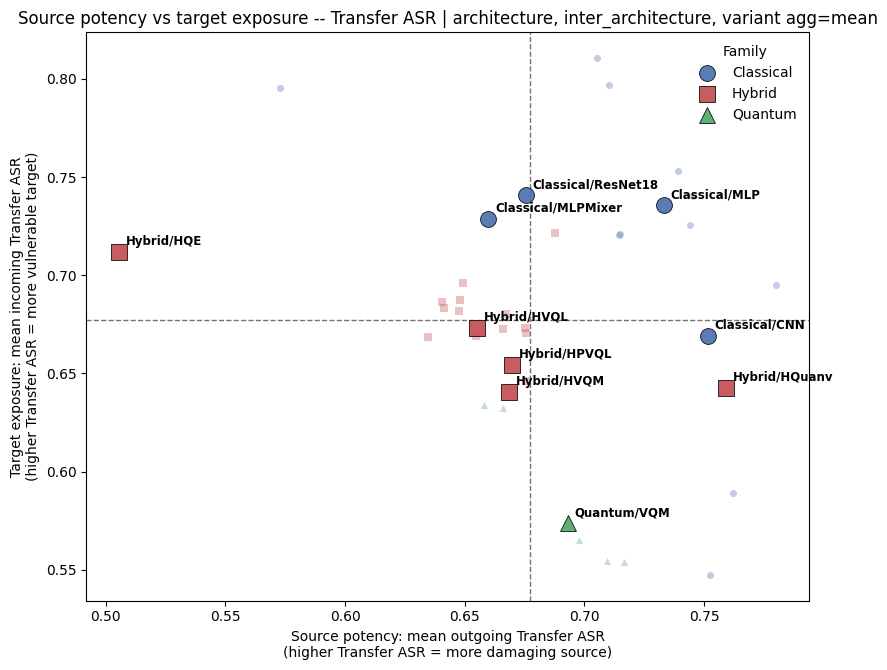

In [8]:
fig, ax = plot_source_target_scatter(
    profile,
    CONFIG,
    title=(f"Source potency vs target exposure -- {CONFIG.metric} | "
           f"{CONFIG.source_grain}, {CONFIG.comparison_mode}, "
           f"variant agg={CONFIG.variant_aggregate_mode}"),
    annotate_fine=ANNOTATE_FINE,
)
export_figure(fig, OUT_DIR, name)